# 5 · Decision chart: what spacing would a 30-year doublet need?

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE**

**This well pair is a test bed, not a power plant.** 16A and 16B are about 96 m apart where they are open; at 10 kg/s the produced water starts to cool within about two years. This notebook asks the design question instead: for well spacing 75–800 m and rates 5–80 kg/s, what produced temperature and heat power would a doublet in this granite give after 30 years, and what spacing keeps the temperature up?

**Method.** A proxy doublet (two parallel laterals in a stimulated slab of fractured granite, same physics as the FORGE model) is tied to the FORGE ensemble: its one free knob, the effective slab thickness, is set so that at 96 m and 10 kg/s it gives the FORGE ensemble's 30-year temperature (P10, P50, P90). Then only spacing and rate change. A Gaussian-process surrogate is trained on full proxy runs, checked on held-out runs, and used for the chart and the Sobol indices.

**Labels.** Proxy runs are **simulated**; the chart and Sobol indices are **surrogate** values (trained on simulations). The chart assumes stimulation at a larger spacing makes a network of the same kind that still connects the wells. FORGE data do not show that.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, FILL, GRANITE, BLUE = "#c9a227", "#26292e", "#d8c7a3", "#b5838d", "#2a78d6"     # KAI energy palette
pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())
PUB = json.loads(pathlib.Path("results/published_phase4.json").read_text()) if pathlib.Path("results/published_phase4.json").exists() else {}
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    return f"{f.format(d['P50'])} ({f.format(d['P10'])}–{f.format(d['P90'])})"
def check(now, key):
    pathlib.Path(f"results/{key}.json").write_text(json.dumps({"published": now}, indent=1))
    if key not in PUB:
        print(f"{key}: no published numbers yet; wrote results/{key}.json")
        return
    bad = []
    for k, v in PUB[key].items():
        x = now[k]
        if isinstance(v, (str, bool)) or v is None or isinstance(x, (str, bool)) or x is None:
            ok = x == v
        else:
            ok = abs(x - v) <= 0.02 * abs(v) + 1e-3
        if not ok:
            bad.append((k, x, v))
    assert not bad, bad
    print(f"all {len(PUB[key])} published numbers reproduced")
print(f"{ens['members'] - ens['failed']}/{ens['members']} members ran; engine results generated {E['generated']}")

20/20 members ran; engine results generated 2026-10-30


## 1 · The FORGE ensemble with Barton–Bandis apertures (30 years)

In [2]:
R = ens["rates"]["barton_bandis"]
rows = []
for q, r in R.items():
    if q == "max_feasible_rate_kg_s":
        continue
    rows.append({"rate (kg/s)": int(q), "T year 1 (°C)": pct(r["T_prod_initial_c"]), "T year 10 (°C)": pct(r["T_prod_10y_c"]), "T year 30 (°C)": pct(r["T_prod_end_c"]),
                 "breakthrough (y, 35 m)": pct(r["breakthrough_years"], "{:.2f}"), "MWth year 1": pct(r["power_initial_mw"]), "MWth year 30": pct(r["power_end_mw"]),
                 "feasible": f"{r['feasible_members']}/{ens['members'] - ens['failed']}"})
display(pd.DataFrame(rows))

,rate (kg/s),T year 1 (°C),T year 10 (°C),T year 30 (°C),"breakthrough (y, 35 m)",MWth year 1,MWth year 30,feasible
0,5,213.7 (212.3–215.5),181.1 (163.8–196.3),153.2 (136.4–169.4),3.50 (1.88–5.48),3.3 (3.2–3.3),2.0 (1.6–2.3),20/20
1,10,213.7 (212.3–215.5),159.3 (137.0–178.5),129.2 (115.7–146.9),1.71 (0.90–2.68),6.4 (6.1–6.6),2.9 (2.3–3.6),7/20
2,20,213.7 (212.3–215.5),134.5 (118.2–156.5),106.4 (99.3–123.3),0.86 (0.43–1.30),12.2 (11.0–12.6),3.9 (3.3–5.3),0/20
3,30,213.7 (212.4–215.4),120.1 (107.7–141.2),95.8 (91.1–110.3),0.55 (0.30–0.81),17.1 (15.0–18.2),4.5 (3.9–6.3),0/20
4,40,213.7 (212.4–215.3),110.6 (101.7–131.0),89.2 (86.2–102.9),0.36 (0.21–0.56),21.3 (18.1–23.2),4.9 (4.4–7.2),0/20


## 2 · Tie to FORGE and the surrogate's error

In [3]:
DC = E["decision"]
tie = DC["tie_to_forge"]
print(f"proxy at 96 m, 10 kg/s: slab {tie['slabs_m']} m gives T30 {[round(t, 1) for t in tie['T30_c']]} °C")
print(f"FORGE targets {({k: round(v, 1) for k, v in tie['targets_c'].items()})} → slab {({k: (None if v is None else round(v, 1)) for k, v in tie['slab_m'].items()})} m")
rows = []
for k, v in DC["surrogate_validation"].items():
    h, cv = v["held_out"]["gp"], v["cross_validation"]
    rows.append({"output": k, "held-out runs": v["held_out"]["n_test"], "RMSE": round(h["rmse"], 3), "max |error|": round(h["max_abs"], 3), "R²": round(h["r2"], 4),
                 "90 % interval coverage": h.get("coverage_90"), "quadratic baseline RMSE": round(v["held_out"]["quadratic_baseline"]["rmse"], 3)})
display(pd.DataFrame(rows))
rows = [{"spacing (m)": c["spacing_m"], "rate (kg/s)": c["rate_kg_s"], "full runs P50 (°C)": round(c["full_P50_c"], 1), "surrogate P50 (°C)": round(c["surrogate_P50_c"], 1),
         "member |error| P50 (°C)": round(c["member_abs_error_c"]["P50"], 2)} for c in DC["chart_full_run_checks"]]
display(pd.DataFrame(rows))

proxy at 96 m, 10 kg/s: slab [8.0, 16.0, 32.0, 64.0, 128.0, 256.0] m gives T30 [88.2, 89.5, 92.2, 98.3, 111.4, 147.4] °C
FORGE targets {'P10': 115.7, 'P50': 129.2, 'P90': 146.9} → slab {'P10': 139.2, 'P50': 180.3, 'P90': 253.5} m


,output,held-out runs,RMSE,max |error|,R²,90 % interval coverage,quadratic baseline RMSE
0,T_prod_end_c,30,9.011,29.576,0.9716,0.800000,25.060
1,power_mean_mw,30,0.796,1.961,0.9889,0.766667,0.919
2,dp_ratio_max,30,3.352,15.885,0.8794,0.966667,5.693


,spacing (m),rate (kg/s),full runs P50 (°C),surrogate P50 (°C),member |error| P50 (°C)
0,100.0,10.0,126.4,123.9,6.70
1,400.0,40.0,109.2,111.4,2.51
2,600.0,80.0,86.9,86.3,1.59


## 3 · The chart

,rate (kg/s),"spacing needed, P50 (m)","spacing needed, P10 (m)"
0,5,193.0,239.0
1,10,290.0,356.0
2,20,580.0,671.0
3,40,NaN,NaN
4,60,NaN,NaN
5,80,NaN,NaN


criterion: produced temperature after 30 years ≥ 198.6 °C (no more than 10 % of the initial − reinjection drop); P10 = the low case also meets it


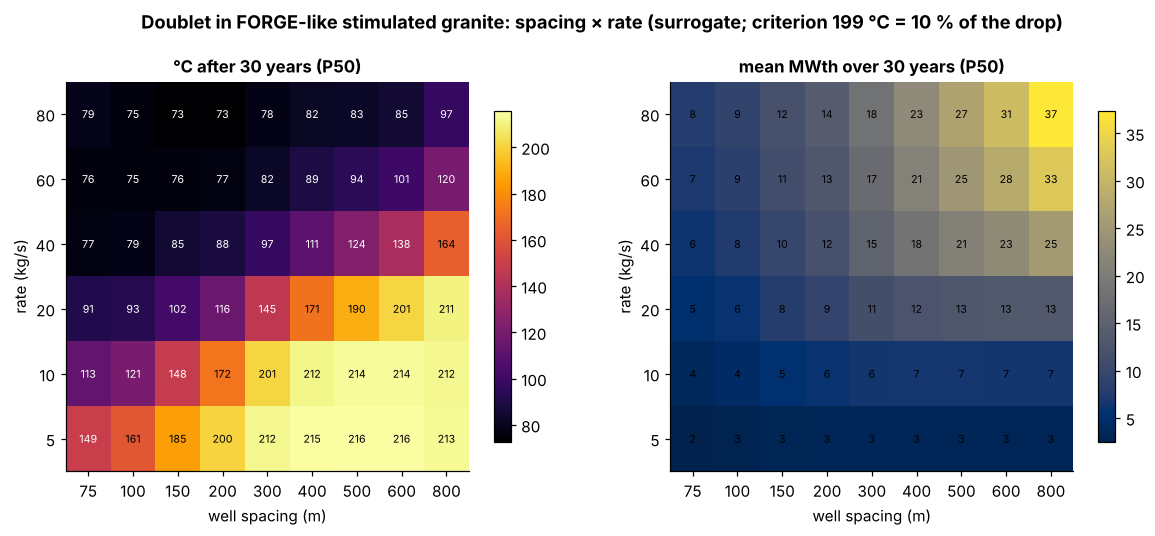

In [4]:
CH = DC["chart"]
Ls, Qs = CH["spacings_m"], CH["rates_kg_s"]
def grid(key, lvl="P50"):
    G = np.full((len(Qs), len(Ls)), np.nan)
    for c in CH["cells"]:
        if key in c:
            G[Qs.index(c["rate_kg_s"]), Ls.index(c["spacing_m"])] = c[key][lvl]
    return G
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a_, key, lab, cmap in ((ax[0], "T30_c", "°C after 30 years (P50)", "inferno"), (ax[1], "power_mean_mw", "mean MWth over 30 years (P50)", "cividis")):
    G = grid(key)
    im = a_.imshow(G, origin="lower", cmap=cmap, aspect="auto")
    for i in range(len(Qs)):
        for j in range(len(Ls)):
            if np.isfinite(G[i, j]):
                a_.text(j, i, f"{G[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if key == "T30_c" and G[i, j] < 150 else "black")
    a_.set_xticks(range(len(Ls)), [f"{L:.0f}" for L in Ls]); a_.set_yticks(range(len(Qs)), [f"{q:.0f}" for q in Qs])
    a_.set_xlabel("well spacing (m)"); a_.set_ylabel("rate (kg/s)"); a_.set_title(lab); fig.colorbar(im, ax=a_, shrink=0.85)
fig.suptitle(f"Doublet in FORGE-like stimulated granite: spacing × rate (surrogate; criterion {CH['T_criterion_c']:.0f} °C = 10 % of the drop)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_decision_chart.png")
rows = [{"rate (kg/s)": int(q), "spacing needed, P50 (m)": (None if v["P50"] is None else round(v["P50"])), "spacing needed, P10 (m)": (None if v["P10"] is None else round(v["P10"]))}
        for q, v in CH["spacing_needed_m"].items()]
display(pd.DataFrame(rows))
print(f"criterion: produced temperature after 30 years ≥ {CH['T_criterion_c']:.1f} °C (no more than 10 % of the initial − reinjection drop); P10 = the low case also meets it")

**Check of the answer with full runs.** The surrogate's 90 % intervals are too narrow (see the table above), so the answer is checked without it: 12 full proxy runs (new draws of the uncertain inputs) at each spacing the chart gives.

In [5]:
SC = DC["spacing_check"]
rows = [{"rate (kg/s)": int(p["rate_kg_s"]), "spacing (m)": round(p["spacing_m"]), "T year 30, full runs (°C)": pct(p["T30_c"]),
         "share meeting the criterion": f"{p['meets_share']:.0%}", "mean MWth": pct(p["power_mean_mw"]), "pressure ratio": pct(p["dp_ratio_max"])} for p in SC["points"]]
display(pd.DataFrame(rows))

,rate (kg/s),spacing (m),"T year 30, full runs (°C)",share meeting the criterion,mean MWth,pressure ratio
0,5,193,203.8 (175.6–211.8),67%,3.2 (3.0–3.3),0.5 (0.4–0.6)
1,10,290,203.6 (173.9–212.5),67%,6.5 (6.1–6.6),1.5 (1.2–3.4)
2,20,580,211.1 (174.8–212.6),75%,13.0 (12.2–13.1),6.2 (4.6–10.2)


## 4 · What matters most (Sobol indices)

Total-order Sobol indices through the surrogates, for the three headline outputs. Two fixed designs (only the uncertain rock inputs vary) and one where spacing and rate vary too. Beside them, the rank correlations of the 20-member FORGE ensemble (too few members for Sobol on the full model).

,output,case,ranking (total order),ST slab_m,ST sigma_lnk,ST corr_m,ST lam,ST spacing_m,ST rate_kg_s
0,T_prod_end_c,forge_spacing_96m_10kgs,slab_m > sigma_lnk > corr_m > lam,0.52,0.40,0.06,0.03,NaN,NaN
1,T_prod_end_c,doublet_400m_40kgs,slab_m > corr_m > sigma_lnk > lam,1.00,0.00,0.00,0.00,NaN,NaN
2,T_prod_end_c,design_and_uncertainty,rate_kg_s > spacing_m > slab_m > sigma_lnk > c...,0.03,0.00,0.00,0.00,0.39,0.67
3,power_mean_mw,forge_spacing_96m_10kgs,sigma_lnk > slab_m > corr_m > lam,0.38,0.52,0.12,0.01,NaN,NaN
4,power_mean_mw,doublet_400m_40kgs,slab_m > sigma_lnk > corr_m > lam,0.89,0.11,0.01,0.00,NaN,NaN
5,power_mean_mw,design_and_uncertainty,rate_kg_s > spacing_m > slab_m > sigma_lnk > c...,0.03,0.00,0.00,0.00,0.43,0.72
6,dp_ratio_max,forge_spacing_96m_10kgs,slab_m > sigma_lnk > lam > corr_m,0.52,0.49,0.00,0.00,NaN,NaN
7,dp_ratio_max,doublet_400m_40kgs,slab_m > sigma_lnk > corr_m > lam,0.62,0.38,0.00,0.00,NaN,NaN
8,dp_ratio_max,design_and_uncertainty,rate_kg_s > spacing_m > slab_m > sigma_lnk > c...,0.02,0.01,0.00,0.00,0.39,0.78


,T30_10kgs_c,breakthrough_10kgs_y,max_feasible_rate_kg_s,stim_aperture_factor
p10_per_m,0.41,0.28,-0.26,0.17
bg_aperture_factor,0.70,0.42,0.41,-0.34
rotation_deg,0.58,0.55,0.10,0.02
stim_aperture_sigma,0.03,-0.19,0.71,-0.70
Kni,0.03,-0.13,0.13,-0.22
Vm,0.18,0.31,-0.50,-0.11


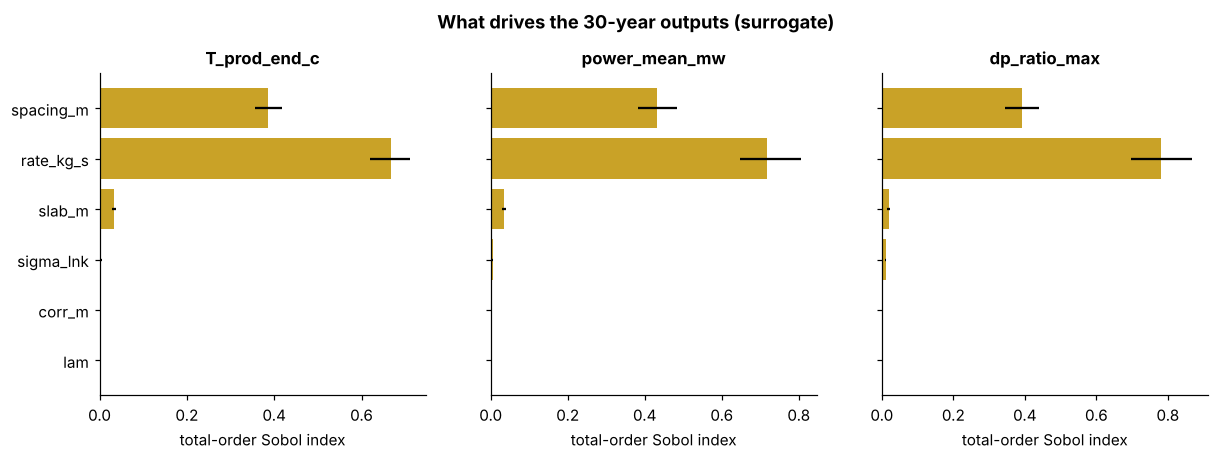

In [6]:
SB = DC["sobol"]["outputs"]
rows = []
for out, d in SB.items():
    for case, s in d.items():
        rows.append({"output": out, "case": case, "ranking (total order)": " > ".join(s["ranking"]),
                     **{f"ST {k}": round(v["ST"], 2) for k, v in s["indices"].items()}})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
names = ["spacing_m", "rate_kg_s", "slab_m", "sigma_lnk", "corr_m", "lam"]
for a_, (out, d) in zip(ax, SB.items()):
    s = d["design_and_uncertainty"]["indices"]
    st = [s[n]["ST"] for n in names]; err = np.array([[s[n]["ST"] - s[n]["ST_ci"][0], s[n]["ST_ci"][1] - s[n]["ST"]] for n in names]).T
    a_.barh(names, st, xerr=np.clip(err, 0, None), color=GOLD); a_.set_title(out); a_.set_xlabel("total-order Sobol index")
ax[0].invert_yaxis(); fig.suptitle("What drives the 30-year outputs (surrogate)", y=1.03, fontweight="bold")
fig.savefig("figures/forge_sobol.png")
sp = E["spearman"]
display(pd.DataFrame({o: {i: round(v["rho"], 2) for i, v in d.items()} for o, d in sp.items()}))

## Published numbers

In [7]:
now = {}
for q in ("5", "10", "20"):
    for k in ("T_prod_end_c", "power_initial_mw", "power_end_mw", "breakthrough_years"):
        for p in ("P10", "P50", "P90"):
            now[f"bb_{q}_{k}_{p}"] = R[q][k][p]
for q, v in CH["spacing_needed_m"].items():
    now[f"spacing_needed_{q}_P50"] = v["P50"]; now[f"spacing_needed_{q}_P10"] = v["P10"]
for k, v in DC["surrogate_validation"].items():
    now[f"rmse_{k}"] = v["held_out"]["gp"]["rmse"]; now[f"r2_{k}"] = v["held_out"]["gp"]["r2"]
for p in DC["spacing_check"]["points"]:
    now[f"check_{int(p['rate_kg_s'])}_T30_P50"] = p["T30_c"]["P50"]; now[f"check_{int(p['rate_kg_s'])}_T30_P10"] = p["T30_c"]["P10"]
for out, d in SB.items():
    now[f"top_{out}"] = d["design_and_uncertainty"]["ranking"][0]
    now[f"top_forge_{out}"] = d["forge_spacing_96m_10kgs"]["ranking"][0]
check(now, "nb5")

all 66 published numbers reproduced


## The plain answer

**This well pair is a test bed, not a power plant.** At 96 m and 10 kg/s the produced water cools from 214 to 129 °C (P10–P90 116–147) in 30 years.

For the produced temperature to stay within 10 % of its drop (at least 198.6 °C) for 30 years, a doublet in this kind of stimulated granite needs about **190 m at 5 kg/s, 290 m at 10 kg/s and 580 m at 20 kg/s** (P50, surrogate). That is 3 × the FORGE spacing at 10 kg/s and 6 × at 20 kg/s. 40 kg/s and more needs more than 800 m.

* Full runs at those spacings give 204, 204 and 211 °C (P50), so the P50 answer holds. Their low cases (P10 174–176 °C) are lower than the surrogate's, so the P10 spacings in the table (240, 360, 670 m) are probably too small.
* Heat: about 3.3 MWth on average at 5 kg/s, 6.5 at 10 kg/s and 13 at 20 kg/s.
* A wider spacing needs more pressure: at 290 m and 10 kg/s about 1.5–1.8 × the August 2024 pressure difference, at 580 m and 20 kg/s about 6–8 ×, at the network conductivity FORGE has now. The August test already ran at Shmin, so such a doublet would also need a network several times more conductive than the 2024 one.
* What matters most (Sobol): the design (rate, then spacing). Among the rock inputs, the effective thickness of the stimulated network, then its heterogeneity. Rock conductivity hardly matters.
* Surrogate error on 30 held-out runs: 9.0 °C RMSE for the 30-year temperature (R² 0.97), 0.80 MW for the heat power, 3.4 for the pressure ratio.

**Limits.** A proxy doublet, tied to FORGE through one output (the 30-year temperature at 10 kg/s). It assumes a network of the same kind can be stimulated at a larger spacing and still connects the wells; FORGE data do not show that. Single-phase water, no new fractures, no thermal or chemical change of the fractures.

*References:* Rasmussen, C. E. and Williams, C. K. I. (2006). Gaussian Processes for Machine Learning. MIT Press · Saltelli, A. et al. (2010). Variance based sensitivity analysis of model output. Comput. Phys. Commun. 181 · Gringarten, A. C. and Sauty, J. P. (1975). A theoretical study of heat extraction from aquifers with uniform regional flow. J. Geophys. Res. 80.